# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Бібліотеки успішно імпортовано!")



Бібліотеки успішно імпортовано!


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Назва файлу:", filename)
print("Розмір датасету:", df.shape)
print("Стовпці:", df.columns.tolist())

display(df.head())




Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv
Назва файлу: house_price_regression_dataset.csv
Розмір датасету: (1000, 8)
Стовпці: ['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price']


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.





## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [3]:
# Завдання 1. Перегляд даних
print("Перші 5 рядків:")
display(df.head())

print("\nРозмір датасету:")
print(df.shape)

print("\nІнформація про стовпці:")
df.info()




Перші 5 рядків:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06



Розмір датасету:
(1000, 8)

Інформація про стовпці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [4]:
print("\nКількість дубльованих рядків:", df.duplicated().sum())





Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [5]:
print("\nКількість пропусків у кожному стовпці:")
print(df.isnull().sum())





Кількість пропусків у кожному стовпці:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [6]:
print("\nОписова статистика:")
display(df.describe())




Описова статистика:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [7]:
print("Частоти Neighborhood_Quality:")
print(df["Neighborhood_Quality"].value_counts().sort_index())


Частоти Neighborhood_Quality:
Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

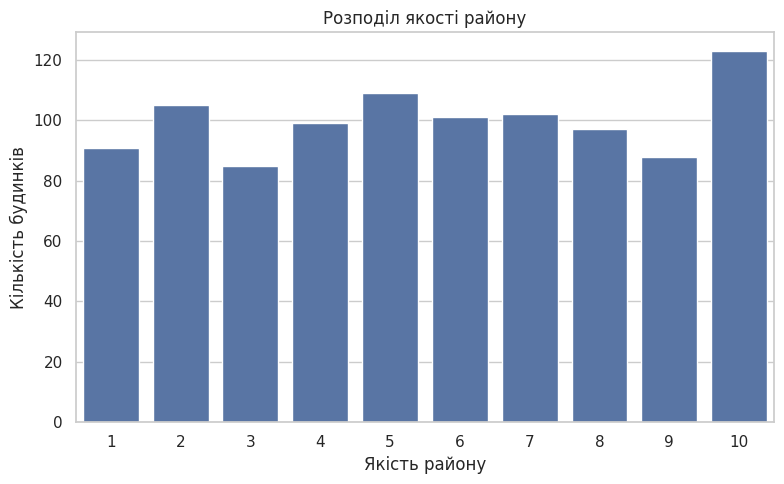

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Neighborhood_Quality")
plt.title("Розподіл якості району")
plt.xlabel("Якість району")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()




### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [9]:
print("Частоти Num_Bathrooms:")
print(df["Num_Bathrooms"].value_counts().sort_index())




Частоти Num_Bathrooms:
Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

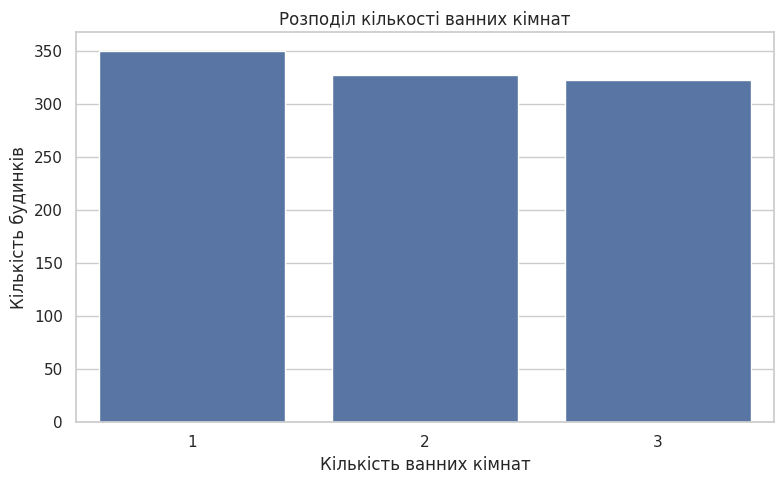

In [10]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Num_Bathrooms")
plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()


### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

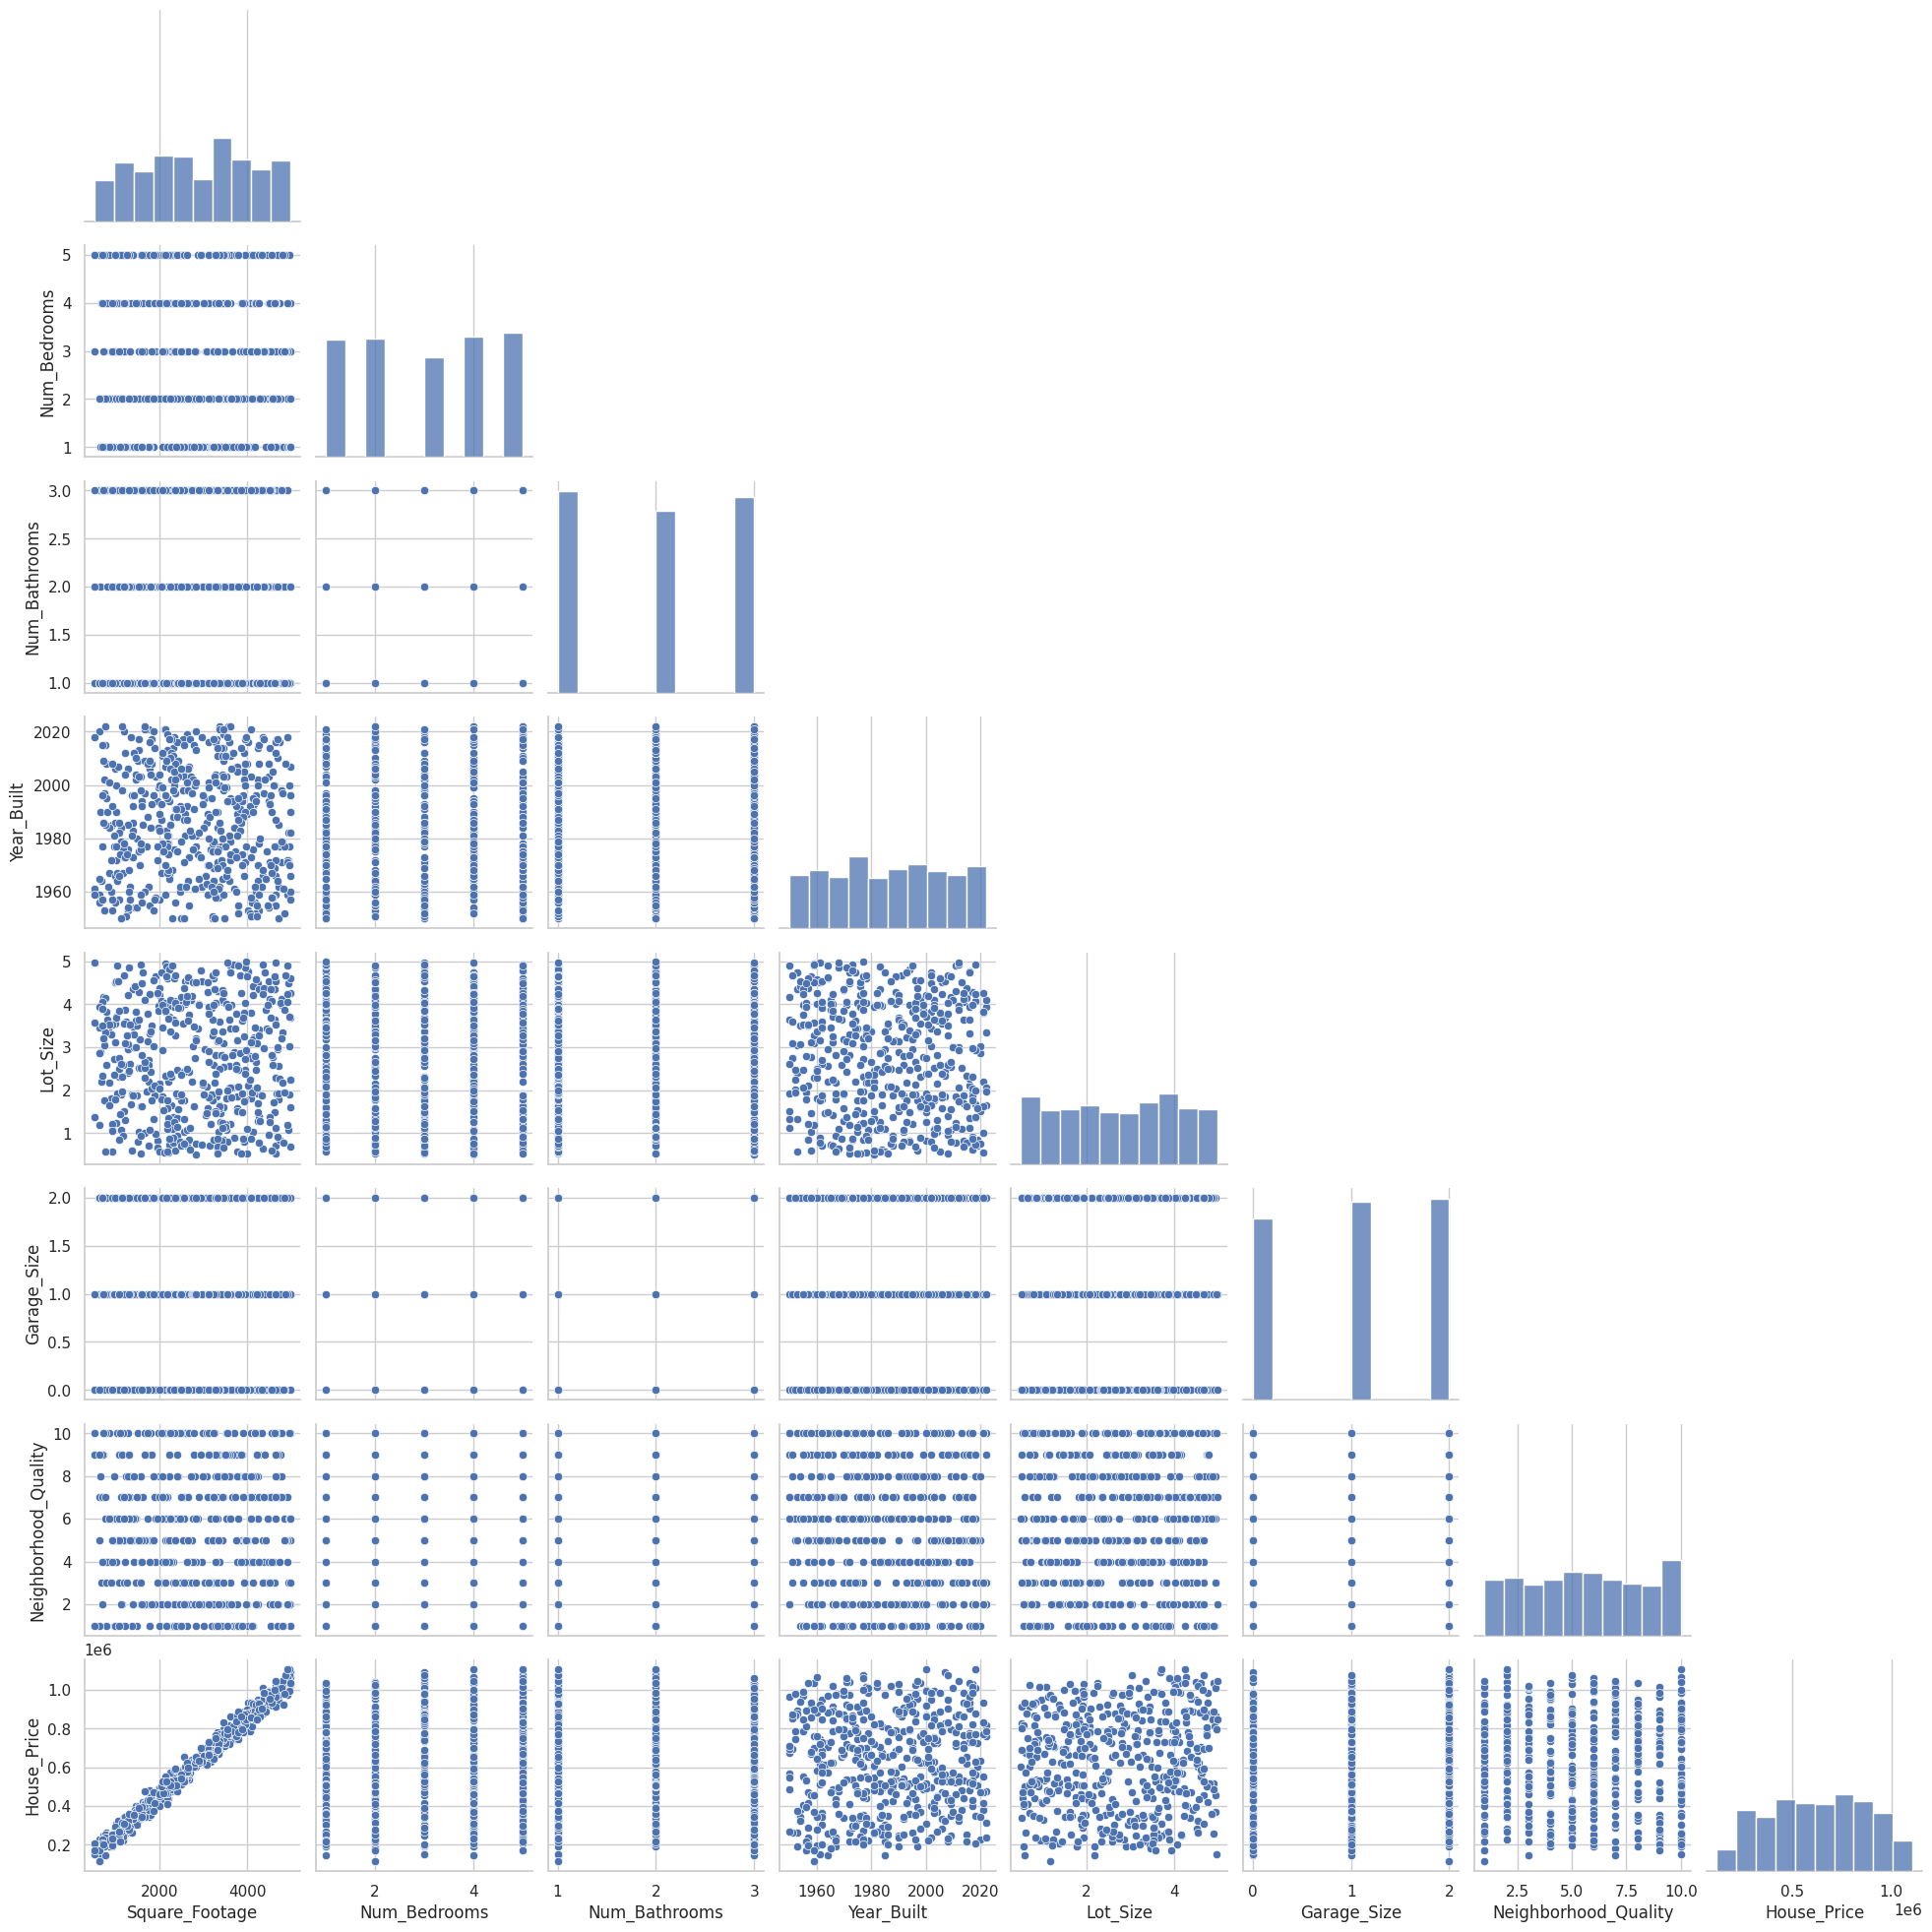

In [11]:

numeric_df = df.select_dtypes(include=np.number)

sns.pairplot(
    numeric_df.sample(min(500, len(numeric_df)), random_state=42),
    corner=True
)
plt.show()


## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

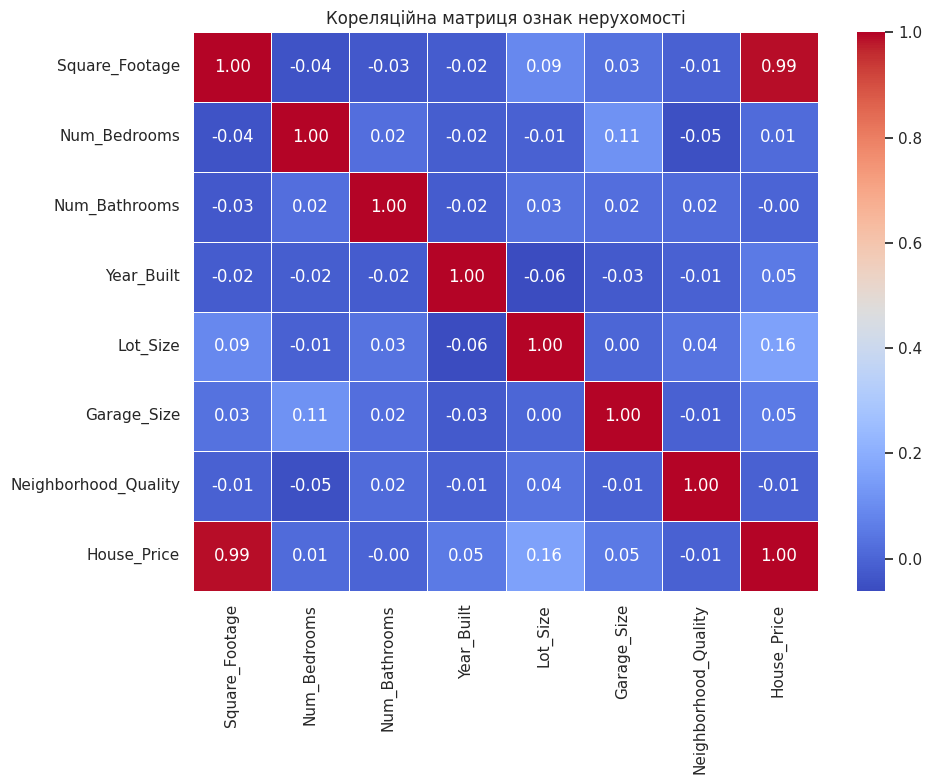

In [12]:
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Кореляційна матриця ознак нерухомості")
plt.tight_layout()
plt.show()



### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [13]:
print("Кореляція ознак із House_Price:")
price_corr = corr_matrix["House_Price"].sort_values(ascending=False)
display(price_corr.to_frame(name="Кореляція з ціною"))



Кореляція ознак із House_Price:


,Кореляція з ціною
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [22]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Бібліотеки успішно імпортовано!")



Бібліотеки успішно імпортовано!


### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [23]:
# X — ознаки будинку
X = df.drop(columns=["House_Price"])

# y — цільова змінна (ціна будинку)
y = df["House_Price"]

print("Ознаки X:")
display(X.head())

print("Цільова змінна y:")
display(y.head())

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)




Ознаки X:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
0,1360,2,1,1981,0.599637,0,5
1,4272,3,3,2016,4.753014,1,6
2,3592,1,2,2016,3.634823,0,9
3,966,1,2,1977,2.730667,1,8
4,4926,2,1,1993,4.699073,0,8


Цільова змінна y:


,House_Price
0,2.623829e+05
1,9.852609e+05
2,7.779774e+05
3,2.296989e+05
4,1.041741e+06


Розмір X: (1000, 7)
Розмір y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки X_train:", X_train.shape)
print("Розмір тестової вибірки X_test:", X_test.shape)
print("Розмір навчальної вибірки y_train:", y_train.shape)
print("Розмір тестової вибірки y_test:", y_test.shape)


Розмір навчальної вибірки X_train: (800, 7)
Розмір тестової вибірки X_test: (200, 7)
Розмір навчальної вибірки y_train: (800,)
Розмір тестової вибірки y_test: (200,)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [14]:

models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

print("Створено моделей:", len(models))
print("Назви моделей:", list(models.keys()))


Створено моделей: 5
Назви моделей: ['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [25]:

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R2", ascending=False
).reset_index(drop=True)

print("Порівняння моделей:")
display(results_df.round(4))


Порівняння моделей:


,Модель,R2,MAE,MSE
0,Linear Regression,0.9984,8174.5836,1.014348e+08
1,Lasso,0.9984,8174.6067,1.014351e+08
2,Ridge,0.9984,8241.5869,1.024810e+08
3,Gradient Boosting,0.9965,12305.2176,2.249656e+08
4,Random Forest,0.9939,16114.2896,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

In [16]:

for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 6))

    plt.scatter(y_test, y_pred, alpha=0.65)

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        label="Ідеальний прогноз"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(f"Фактичні та прогнозовані ціни: {name}")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [26]:

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_features": [1.0, "sqrt"],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкращий середній R² на крос-валідації:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри:
{'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Найкращий середній R² на крос-валідації:
0.992


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [27]:
best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)

best_metrics = {
    "Модель": "Random Forest (оптимізована)",
    "R2": r2_score(y_test, best_pred),
    "MAE": mean_absolute_error(y_test, best_pred),
    "MSE": mean_squared_error(y_test, best_pred)
}

print("Метрики оптимізованої моделі:")
display(pd.DataFrame([best_metrics]).round(4))


Метрики оптимізованої моделі:


,Модель,R2,MAE,MSE
0,Random Forest (оптимізована),0.994,16035.1681,3.872291e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [28]:
baseline_metrics = results_df[
    results_df["Модель"] == "Random Forest"
].iloc[0]

comparison_df = pd.DataFrame([
    {
        "Модель": "Random Forest (базова)",
        "R2": baseline_metrics["R2"],
        "MAE": baseline_metrics["MAE"],
        "MSE": baseline_metrics["MSE"]
    },
    best_metrics
])

print("Порівняння до і після оптимізації:")
display(comparison_df.round(4))

# Автоматичний аналіз результату
r2_change = best_metrics["R2"] - baseline_metrics["R2"]
mae_change = best_metrics["MAE"] - baseline_metrics["MAE"]
mse_change = best_metrics["MSE"] - baseline_metrics["MSE"]

print("\nВисновок щодо оптимізації:")
print(f"Зміна R²: {r2_change:+.4f}")
print(f"Зміна MAE: {mae_change:+.4f}")
print(f"Зміна MSE: {mse_change:+.4f}")

if (
    r2_change > 0
    and mae_change < 0
    and mse_change < 0
):
    print("Оптимізація покращила всі три метрики.")
elif (
    r2_change < 0
    and mae_change > 0
    and mse_change > 0
):
    print("Після оптимізації всі три метрики погіршилися.")
else:
    print("Результат змішаний: оцініть кожну метрику окремо.")

Порівняння до і після оптимізації:


,Модель,R2,MAE,MSE
0,Random Forest (базова),0.9939,16114.2896,3.941317e+08
1,Random Forest (оптимізована),0.9940,16035.1681,3.872291e+08



Висновок щодо оптимізації:
Зміна R²: +0.0001
Зміна MAE: -79.1216
Зміна MSE: -6902655.5246
Оптимізація покращила всі три метрики.


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [29]:

linear_pred = predictions["Linear Regression"]

forecast_df = pd.DataFrame({
    "Фактична ціна": np.asarray(y_test),
    "Прогнозована ціна": linear_pred
})

# Відносна похибка у відсотках.
# Для нульової фактичної ціни похибка не визначається.
actual = forecast_df["Фактична ціна"].to_numpy()
predicted = forecast_df["Прогнозована ціна"].to_numpy()

forecast_df["Похибка, %"] = np.where(
    actual != 0,
    np.abs(actual - predicted) / np.abs(actual) * 100,
    np.nan
)

print("10 випадкових прогнозів:")
display(
    forecast_df.sample(
        n=min(10, len(forecast_df)),
        random_state=42
    ).round(2)
)

10 випадкових прогнозів:


,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

In [30]:

# Визначення найкращої моделі за R²
best_model_row = results_df.iloc[0]

print("ЗАГАЛЬНИЙ ВИСНОВОК")
print("-" * 50)

print(
    "У лабораторній роботі було виконано первинний аналіз "
    "даних про нерухомість, досліджено розподіли ознак "
    "і побудовано кореляційну матрицю."
)

print(
    "\nБуло побудовано п'ять моделей регресії: "
    "Linear Regression, Ridge, Lasso, Random Forest "
    "і Gradient Boosting."
)

print(
    f"\nНайкраща модель за R² серед базових моделей: "
    f"{best_model_row['Модель']}."
)
print(f"R² = {best_model_row['R2']:.4f}")
print(f"MAE = {best_model_row['MAE']:.4f}")
print(f"MSE = {best_model_row['MSE']:.4f}")

print(
    "\nПісля цього було виконано підбір гіперпараметрів "
    "Random Forest за допомогою GridSearchCV "
    "з п'ятичастинною крос-валідацією."
)

print(
    f"R² базового Random Forest: "
    f"{baseline_metrics['R2']:.4f}"
)
print(
    f"R² оптимізованого Random Forest: "
    f"{best_metrics['R2']:.4f}"
)

print(
    "\nЯкість прогнозування оцінювалася за метриками R², "
    "MAE та MSE. Чим ближче R² до 1 і чим менші MAE "
    "та MSE, тим кращими є прогнози."
)

print(
    "\nНа точність прогнозування можуть впливати площа будинку, "
    "кількість спалень і ванних кімнат, рік побудови, "
    "розмір ділянки, розмір гаража, якість району, "
    "наявність пропущених значень та обсяг навчальних даних."
)

print(
    "\nОстаточний вибір моделі потрібно робити за фактичними "
    "результатами тестування та порівняння всіх метрик."
)

ЗАГАЛЬНИЙ ВИСНОВОК
--------------------------------------------------
У лабораторній роботі було виконано первинний аналіз даних про нерухомість, досліджено розподіли ознак і побудовано кореляційну матрицю.

Було побудовано п'ять моделей регресії: Linear Regression, Ridge, Lasso, Random Forest і Gradient Boosting.

Найкраща модель за R² серед базових моделей: Linear Regression.
R² = 0.9984
MAE = 8174.5836
MSE = 101434798.5056

Після цього було виконано підбір гіперпараметрів Random Forest за допомогою GridSearchCV з п'ятичастинною крос-валідацією.
R² базового Random Forest: 0.9939
R² оптимізованого Random Forest: 0.9940

Якість прогнозування оцінювалася за метриками R², MAE та MSE. Чим ближче R² до 1 і чим менші MAE та MSE, тим кращими є прогнози.

На точність прогнозування можуть впливати площа будинку, кількість спалень і ванних кімнат, рік побудови, розмір ділянки, розмір гаража, якість району, наявність пропущених значень та обсяг навчальних даних.

Остаточний вибір моделі потрібно